![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Pipelines and Models

*Project 2 — Machine Learning: From Data to Predictions*

**Team:**
**Dataset:**

---

Steps 5 to 8 of the workflow: build the pipeline, compare models fairly, tune the best, and choose the threshold. Everything here uses the training set only.

> **Done when:** you have a comparison table of at least three model families on the same folds against the baseline, the best one or two tuned, and a final model chosen for reasons you can state.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. Load and split

The same loading and the same split as notebook 01. Put the code in `src/functions.py` so both notebooks use exactly the same rows.

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict
from scipy.stats import loguniform, randint

data = clean_data(load_data())
X_train, X_test, y_train, y_test = split_data(data)

cv = make_cv()
scoring = make_scoring()

print(len(X_train), "training rows,", len(X_test), "test rows")

32940 training rows, 8236 test rows


Same rows and same split as in notebook 01, and the same 5 folds for every model. The test set stays untouched in this notebook. The baseline to beat is F1 = 0.203 (always "yes").

---
## 2. The preprocessing pipeline

A `ColumnTransformer` with one branch per column type: impute, scale, encode. **Everything that learns from data goes inside**, so cross-validation refits it on every fold.

In [3]:
build_pipeline(LogisticRegression(max_iter=1000))

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function add...t 0x16d62a200>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,{}


The pipeline has three steps:

- `features`: the new features from notebook 01, switched off for now
- `prep`: `StandardScaler` for the numeric columns and `OneHotEncoder(handle_unknown="ignore")` for the categorical ones, so `unknown` just becomes its own category
- `model`

No imputer, since there are no `NaN`s. Raw rows go in, so nothing gets fitted outside of the pipeline.

---
## 3. First model in the pipeline

One simple model at the end of the pipeline, scored with cross-validation. Is it better than the baseline, and by more than the spread across folds?

In [4]:
first = {
    "logistic regression": build_pipeline(LogisticRegression(max_iter=1000)),
    "logistic regression, balanced": build_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")),
}
compare_models(first, X_train, y_train, cv, scoring)

,F1,F1 std,recall,precision,accuracy
model,,,,,
logistic regression,0.34,0.004,0.229,0.661,0.900
"logistic regression, balanced",0.45,0.008,0.622,0.353,0.829


Plain logistic regression already beats the baseline: F1 0.340 vs 0.203, and the spread across the folds is tiny (0.004). But it plays it really safe: it only finds 23% of the subscribers (recall), even though 66% of the clients it flags actually say yes.

With `class_weight="balanced"` it finds 62% of them and F1 jumps to 0.450. Precision drops to 35%, so more wasted calls, but since a missed yes is worse, that's the better deal. From here on I go with the balanced version.

---
## 4. Features

New features added inside the pipeline. Keep a feature only if it improves the cross-validated score, and write down what each one changed.

In [5]:
lr_balanced = lambda: LogisticRegression(max_iter=1000, class_weight="balanced")

feature_tests = {
    "no new features": build_pipeline(lr_balanced()),
    "+ age groups": build_pipeline(lr_balanced(), age_groups=True),
    "contacted flag instead of pdays": build_pipeline(lr_balanced(), contacted_flag=True),
    "only euribor3m of the economy trio": build_pipeline(lr_balanced(), one_economy=True),
    "without housing and loan": build_pipeline(lr_balanced(), drop=("housing", "loan")),
    "all of the above": build_pipeline(lr_balanced(), age_groups=True, contacted_flag=True,
                                       one_economy=True, drop=("housing", "loan")),
}
compare_models(feature_tests, X_train, y_train, cv, scoring)

,F1,F1 std,recall,precision,accuracy
model,,,,,
no new features,0.450,0.008,0.622,0.353,0.829
+ age groups,0.453,0.009,0.625,0.355,0.830
contacted flag instead of pdays,0.450,0.008,0.624,0.352,0.828
only euribor3m of the economy trio,0.440,0.011,0.627,0.339,0.820
without housing and loan,0.451,0.008,0.623,0.354,0.829
all of the above,0.440,0.011,0.626,0.339,0.820


All changes happen inside the pipeline (`add_features` in `src/functions.py`). What they did:

- **age groups**: 0.453 instead of 0.450. That's less than the spread across the folds (~0.009), so not a real improvement. Not kept
- **contacted flag instead of `pdays`**: exactly the same score. Keeping it anyway, because it swaps the column full of 999s for a simple yes/no without losing anything
- **only `euribor3m`**: drops to 0.440. So the three economy columns aren't completely redundant after all. Not kept
- **without `housing` and `loan`**: 0.451, same as before. Like the EDA already showed, they don't add anything, so they're out: two columns less for the same score
- **all of the above**: 0.440, dragged down by the economy change

So the features for all the next models: contacted flag instead of `pdays`, and no `housing` and `loan`.

---
## 5. Compare models

At least three model families on **the same folds**, with the mean and the spread. A table, and a chart of it.

Only 11% of the clients said yes, so before picking a model I decide how to deal with that. Every model family gets every method, so no model is judged on a method that doesn't suit it:

- **none**: the plain model
- **class weights**: `class_weight="balanced"`, a mistake on a yes client counts about 8× more
- **random oversampling**: copies yes clients until both classes are the same size
- **SMOTE**: makes new synthetic yes clients in between existing ones
- **random undersampling**: throws away no clients until both classes are the same size
- **cluster centroids**: groups the no clients with k-means and keeps only the centre of each group (undersampling by clustering)

The resampling only happens inside the training folds (`imblearn` pipeline), so every validation fold keeps its real share of yes.

Each combination gets two scores: F1 at the default threshold 0.5, and the best F1 at any threshold. The second one is the fair comparison, because most of these methods mainly move the threshold where a model does best.

In [6]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler, ClusterCentroids
from sklearn.cluster import MiniBatchKMeans

FEATURES = dict(contacted_flag=True, drop=("housing", "loan"))

def make_models(class_weight):
    return {
        "logistic regression": LogisticRegression(max_iter=1000, class_weight=class_weight),
        "decision tree": DecisionTreeClassifier(class_weight=class_weight, random_state=RANDOM_STATE),
        "random forest": RandomForestClassifier(n_estimators=300, class_weight=class_weight,
                                                random_state=RANDOM_STATE, n_jobs=-1),
        "gradient boosting": HistGradientBoostingClassifier(class_weight=class_weight, random_state=RANDOM_STATE),
    }

samplers = {
    "none": None,
    "class weights": "balanced",
    "random oversampling": RandomOverSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "random undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "cluster centroids": ClusterCentroids(estimator=MiniBatchKMeans(n_init=1, random_state=RANDOM_STATE),  # same as k-means, much faster
                                          random_state=RANDOM_STATE),
}

imbalance = compare_imbalance(make_models, samplers, X_train, y_train, cv, **FEATURES)
imbalance.pivot(index="model", columns="imbalance", values="F1 at 0.5")[list(samplers)]

imbalance,none,class weights,random oversampling,SMOTE,random undersampling,cluster centroids
model,,,,,,
decision tree,0.337,0.317,0.319,0.338,0.290,0.218
gradient boosting,0.365,0.475,0.469,0.426,0.440,0.203
logistic regression,0.337,0.451,0.450,0.442,0.446,0.422
random forest,0.376,0.370,0.414,0.418,0.392,0.227


F1 at the default threshold 0.5 (above) and the best F1 at any threshold (below):

In [7]:
imbalance.pivot(index="model", columns="imbalance", values="best F1")[list(samplers)]

imbalance,none,class weights,random oversampling,SMOTE,random undersampling,cluster centroids
model,,,,,,
decision tree,0.337,0.318,0.319,0.338,0.290,0.218
gradient boosting,0.497,0.499,0.497,0.494,0.490,0.209
logistic regression,0.483,0.484,0.485,0.481,0.479,0.479
random forest,0.446,0.439,0.430,0.441,0.466,0.407


The best combination per model family, with the spread across the folds:

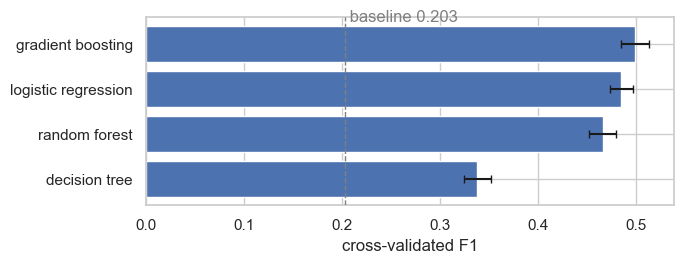

,imbalance,F1 at 0.5,F1,F1 std,at threshold,recall,precision
model,,,,,,,
gradient boosting,class weights,0.475,0.499,0.014,0.65,0.566,0.446
logistic regression,random oversampling,0.450,0.485,0.012,0.65,0.565,0.425
random forest,random undersampling,0.392,0.466,0.014,0.75,0.502,0.434
decision tree,SMOTE,0.338,0.338,0.014,0.35,0.371,0.310


In [8]:
baseline = compare_models({"baseline (always yes)": DummyClassifier(strategy="constant", constant=1)},
                          X_train, y_train, cv, scoring)

best = imbalance.loc[imbalance.groupby("model")["best F1"].idxmax()].set_index("model")
best = best.rename(columns={"best F1": "F1"}).sort_values("F1", ascending=False)
plot_comparison(best, baseline.loc["baseline (always yes)", "F1"])
best

What the two tables show:

- **at 0.5 the method seems to matter a lot**: gradient boosting goes from 0.365 (none) to 0.475 (class weights), logistic regression from 0.337 to 0.451
- **at the best threshold most of that is gone**: for gradient boosting and logistic regression all methods except cluster centroids end up within ~0.01 of each other, which is the spread across the folds. The methods mostly just move the threshold (gradient boosting does best at 0.20 without handling and at 0.65 with class weights)
- **the 0.5 comparison was unfair to the random forest**: 0.376 at 0.5 but 0.446 at its best threshold, and 0.466 with random undersampling. Still clearly behind the other two
- **cluster centroids hurts**: it replaces ~26,000 no clients with ~3,000 averaged points that aren't real clients. Gradient boosting falls back to the baseline (0.209)
- **the decision tree stays last** whatever I do. It grows until it fits the training data, so it has no useful probabilities to move a threshold on

The model family matters, the imbalance method hardly does. **Gradient boosting** wins (0.499), then **logistic regression** (0.485). The gap (0.014) is about as big as the spread across the folds, but on the same folds gradient boosting is ahead in every single one (by 0.012 to 0.020), so the lead is real, just small.

For the method I take **class weights**: as good as any other, no extra library, and no clients copied, made up or thrown away. So I tune the two best ones: gradient boosting and logistic regression, both with class weights.

---
## 6. Tune

A `GridSearchCV` or `RandomizedSearchCV` on the best one or two, on the training set. Report the best parameters and the cross-validated score.

In [9]:
lr_search = GridSearchCV(
    build_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced"), **FEATURES),
    {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=cv, scoring="f1", n_jobs=-1)
lr_search.fit(X_train, y_train)

print("Best settings:", lr_search.best_params_)
print(f"Best cross-validated F1: {lr_search.best_score_:.3f}")
pd.DataFrame(lr_search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]].round(3)

Best settings: {'model__C': 100}
Best cross-validated F1: 0.451


,param_model__C,mean_test_score,std_test_score
0,0.001,0.395,0.011
1,0.010,0.436,0.013
2,0.100,0.449,0.009
3,1.000,0.451,0.009
4,10.000,0.451,0.009
5,100.000,0.451,0.009


`C` (how strongly the model gets held back) barely matters from 0.1 upwards, everything is at 0.449–0.451. The default `C=1` is already as good as the best one, so no change for logistic regression.

In [10]:
hgb_params = {
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__max_leaf_nodes": randint(8, 64),
    "model__min_samples_leaf": randint(20, 200),
    "model__l2_regularization": loguniform(1e-3, 10),
}
hgb_search = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE), **FEATURES),
    hgb_params, n_iter=20, cv=cv, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
hgb_search.fit(X_train, y_train)

print("Best settings:", hgb_search.best_params_)
print(f"Best cross-validated F1: {hgb_search.best_score_:.3f}")
results = pd.DataFrame(hgb_search.cv_results_).sort_values("rank_test_score")
results[[c for c in results.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]].head().round(3)

Best settings: {'model__l2_regularization': np.float64(0.015314189711654769), 'model__learning_rate': np.float64(0.01754362390093243), 'model__max_leaf_nodes': 32, 'model__min_samples_leaf': 90}
Best cross-validated F1: 0.475


,param_model__l2_regularization,param_model__learning_rate,param_model__max_leaf_nodes,param_model__min_samples_leaf,mean_test_score,std_test_score
19,0.015,0.018,32,90,0.475,0.015
1,0.248,0.017,26,94,0.475,0.016
6,0.015,0.080,49,34,0.474,0.013
16,0.811,0.030,21,59,0.473,0.013
12,0.096,0.011,21,100,0.471,0.020


20 random combinations, and the best one gets 0.475. The default settings had 0.475 at the same threshold 0.5, so tuning didn't help here either. Looks like the defaults of gradient boosting already fit this data pretty well.

Since the tuned versions aren't better, I keep both models with their default settings. Simpler, and nothing lost.

---
## 7. Threshold

Classification only. Cross-validated probabilities on the training set with `cross_val_predict`, then the threshold that fits your metric and the cost of each mistake. Regression: delete this section and say why in the README.

In [11]:
best_model = build_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE), **FEATURES)
proba_cv = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = threshold_table(y_train, proba_cv, np.arange(0.3, 0.81, 0.05))
thresholds

,F1,recall,precision,calls,missed yes,wasted calls
threshold,,,,,,
0.30,0.297,0.833,0.181,17093,619,14001
0.35,0.348,0.764,0.225,12578,877,9744
0.40,0.411,0.686,0.293,8692,1164,6145
0.45,0.452,0.650,0.346,6972,1299,4560
0.50,0.475,0.625,0.384,6044,1392,3725
0.55,0.488,0.598,0.412,5389,1490,3168
0.60,0.496,0.582,0.432,4998,1550,2837
0.65,0.499,0.566,0.446,4711,1610,2610
0.70,0.496,0.542,0.457,4401,1701,2391


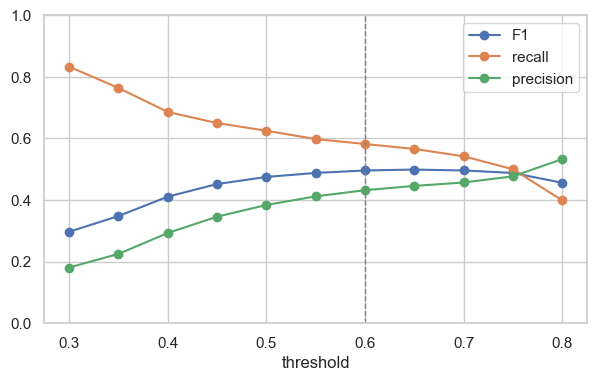

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
for col in ["F1", "recall", "precision"]:
    ax.plot(thresholds.index, thresholds[col], marker="o", label=col)
ax.axvline(FINAL_THRESHOLD, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("threshold")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

Every client gets a probability, and the threshold decides from which probability on we call them. The lower it is, the more clients get called: more subscribers found (recall up), but more wasted calls (precision down).

- F1 is highest at **0.65** (0.499)
- at the default 0.5 it's only 0.475

Since a missed yes is worse than a wasted call, I don't just take the highest F1. I take the lowest threshold where F1 is still within the spread across the folds (~0.01) of the best one. That's **0.60** (F1 0.496). Compared to 0.65 the model finds 60 more subscribers and makes 227 more wasted calls.

At 0.60 the model would call 4,998 of the 32,940 clients (15%) and reach 58% of all subscribers. Calling everyone reaches all of them, but with almost 29,000 wasted calls.

Logistic regression gets 0.485 at most at any threshold (section 5), so gradient boosting stays ahead after picking the threshold too.

---
## 8. The final model

Which model, which parameters, which threshold, and why. If a simpler model is within the noise of the best one, say which you chose and why.

- **model:** `HistGradientBoostingClassifier` with `class_weight="balanced"` and default settings
- **features:** all columns except `duration`, `housing` and `loan`, with a "contacted before" flag instead of `pdays`
- **threshold:** 0.60
- **cross-validated F1:** 0.496 at that threshold, vs 0.203 for the baseline

Why this one: it had the best F1 in the comparison and also after picking the threshold. Logistic regression is simpler and easier to explain, but it stays behind: by 0.014 at the best threshold, and gradient boosting wins on every one of the 5 folds. Tuning didn't improve either model, so the default settings stay. Against the imbalance I use class weights plus the 0.60 threshold. Resampling (random over- or undersampling, SMOTE) gets the same F1 at its best threshold, so there's no reason for the extra step.

The final model lives in `src/functions.py` (`final_pipeline()` and `FINAL_THRESHOLD`), so notebook 03 builds exactly the same one.

---
## Image option

If you chose the flower photos, sections 2 to 7 become: rescaling and augmentation layers; a CNN from scratch trained with early stopping, with its training curves; a frozen pretrained network (for example `MobileNetV2`) with a new output layer, trained the same way; and the two compared on the validation set. Fine-tuning the top of the pretrained network is optional.